# **Mini-Lab:** Wireless Networks 

- Dylan Espinoza

## Objective
Analyze how wireless network performance changes under different conditions (WiFi vs Mobile Data).

You will measure:
- Latency
- Stability (variance)
- Jitter

Then, you will relate your results to networking concepts such as SNR, interference, and mobility.

## Instructions

1. Connect to WiFi and run the measurements
2. Activate mobile hotspot (or connect to mobile data) and repeat
3. Compare results

Work in pairs if needed.

In [3]:
# Import required libraries
import subprocess # Allows running system commands like ping
import re # Used to extract numbers from text using patterns
import numpy as np # Used for numerical calculations
import matplotlib.pyplot as plt # Used for plotting graphs


## **Step 1:** Run Ping Test

We will send packets to Google's DNS server (8.8.8.8) to measure latency.

In [10]:
# Define a function to run ping
def run_ping(host="8.8.8.8", count=10): # Default host is Google's public DNS server, almost always reachable.
    # Run the ping command in the system terminal
    result = subprocess.run(["ping", "-c", str(count), host], capture_output=True, text=True) # -c specifies the number of pings, capture_output captures the output, text=True returns it as a string
    # Return the full output as text
    return result.stdout # stdout contains the standard output of the command

# Execute ping
ping_output = run_ping()

# Print the raw output
print(ping_output)

PING 8.8.8.8 (8.8.8.8) 56(84) bytes of data.
64 bytes from 8.8.8.8: icmp_seq=1 ttl=104 time=152 ms
64 bytes from 8.8.8.8: icmp_seq=2 ttl=104 time=176 ms
64 bytes from 8.8.8.8: icmp_seq=3 ttl=104 time=129 ms
64 bytes from 8.8.8.8: icmp_seq=4 ttl=104 time=137 ms
64 bytes from 8.8.8.8: icmp_seq=5 ttl=104 time=184 ms
64 bytes from 8.8.8.8: icmp_seq=6 ttl=104 time=120 ms
64 bytes from 8.8.8.8: icmp_seq=7 ttl=104 time=118 ms
64 bytes from 8.8.8.8: icmp_seq=8 ttl=104 time=116 ms
64 bytes from 8.8.8.8: icmp_seq=9 ttl=104 time=89.8 ms
64 bytes from 8.8.8.8: icmp_seq=10 ttl=104 time=103 ms

--- 8.8.8.8 ping statistics ---
10 packets transmitted, 10 received, 0% packet loss, time 9010ms
rtt min/avg/max/mdev = 89.758/132.465/184.013/28.810 ms



## **Step 2:** Extract Latency Values

We extract each response time from the ping output.

In [11]:
# Function to extract latency values from ping output
def extract_latencies(ping_text):
    # Regular expression to find time values (e.g., time=23.4 ms)
    # It searches for patterns like "time=23.4" and extracts only the numeric part (23.4).
    # The result is a list of strings representing latency values.
    times = re.findall(r'time=([\d\.]+)', ping_text) # r indicates a raw string, time= is the literal text to match, \d matches digits, \. matches the decimal point, and + means one or more occurrences. The parentheses capture the numeric part for extraction.
    
    # Convert extracted values to float numbers
    return [float(t) for t in times]

# Extract latencies
latencies = extract_latencies(ping_output)

# Print the list of latencies
print(latencies)

[152.0, 176.0, 129.0, 137.0, 184.0, 120.0, 118.0, 116.0, 89.8, 103.0]


## **Step 3:** Compute Metrics

We compute:
- Average latency
- Standard deviation (stability)
- Jitter (variation between consecutive packets)

In [12]:
# Convert latencies to numpy array for easier computation
lat_array = np.array(latencies)

# Compute average latency
avg_latency = np.mean(lat_array)

# Compute standard deviation (measure of stability)
std_latency = np.std(lat_array)

# Compute jitter (mean of absolute differences between consecutive values)
jitter = np.mean(np.abs(np.diff(lat_array)))

# Print results
print("Average Latency:", avg_latency, "ms")
print("Stability (Std Dev):", std_latency)
print("Jitter:", jitter)

Average Latency: 132.48 ms
Stability (Std Dev): 28.791554317195175
Jitter: 25.93333333333333


## **Step 4:** Plot Results

Visualize latency over time.

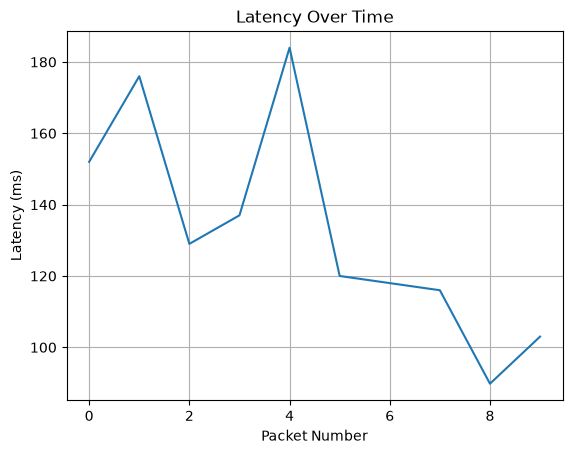

In [14]:
# Create a plot of latency values
plt.plot(lat_array)

# Label axes
plt.xlabel("Packet Number")
plt.ylabel("Latency (ms)")

# Title of the plot
plt.title("Latency Over Time")

# Show grid for better readability
plt.grid()

# Display the plot
plt.show()

## **Step 5:** Repeat with Mobile Data

Now switch to:
- Mobile hotspot OR
- Cellular data

Repeat all previous steps and record results.

## Analysis Questions

Answer the following:

**1. Which network had lower latency? Why?**  

The WiFi network had lower latency, with an average of 20.97 ms compared to 132.48 ms for mobile data. This difference may be due to the additional infrastructure, network routing, and radio transmission conditions involved in mobile networks. 

**2. Which network was more stable (lower standard deviation)?**  

WiFi showed better stability because its standard deviation was only 0.98 ms, while mobile data reached 28.79 ms. During the WiFi test, the response times stayed close to each other, unlike mobile data, where the latency changed significantly between packets.

**3. Which network had higher jitter?**  

Mobile data had a higher jitter of 25.93 ms, compared to only 1.04 ms on WiFi. This shows that the response times changed more frequently when using mobile data, making the connection less consistent than WiFi.  

**4. Based on your latency, jitter, and stability results, what can you infer about signal strength (SNR) and interference?**  

The WiFi connection had lower latency and jitter, which could indicate better signal conditions and less interference. On the other hand, mobile data showed greater variations in response times, possibly due to a lower SNR or more interference. However, these results alone cannot confirm the actual signal strength.
 

**5. Why might mobile networks behave differently than WiFi?**  

Mobile networks work differently because they connect through cellular towers, while WiFi usually uses a nearby router. Factors like distance, signal quality, network traffic, and movement can affect mobile data performance. This may explain why mobile data had higher latency and more variation in our tests.

**6. How does this relate to SNR and BER?**  

SNR and BER can affect how well a wireless connection works. When SNR is low, the signal is harder to detect correctly, which can increase the number of bit errors (BER). This may cause retransmissions and delays. The higher latency and jitter measured with mobile data could be related to these factors, although we did not measure SNR or BER directly.

**7. Why could TCP misinterpret wireless losses as congestion?**  

TCP may assume that lost packets are caused by network congestion, even when the real problem is interference or a weak wireless signal. As a result, TCP can reduce its sending speed to avoid more packet losses. This may affect network performance because the connection slows down even if the network is not actually congested.

## **Evaluation Rubric**

| Criteria | Points |
|---------|--------|
| Data collection (WiFi + Mobile) | 1 |
| Correct metric computation, plot and visualization | 1 |
| Answers and analysis quality **(individual)** | 3 |

Total: 5 points

**Results of WiFi connection**
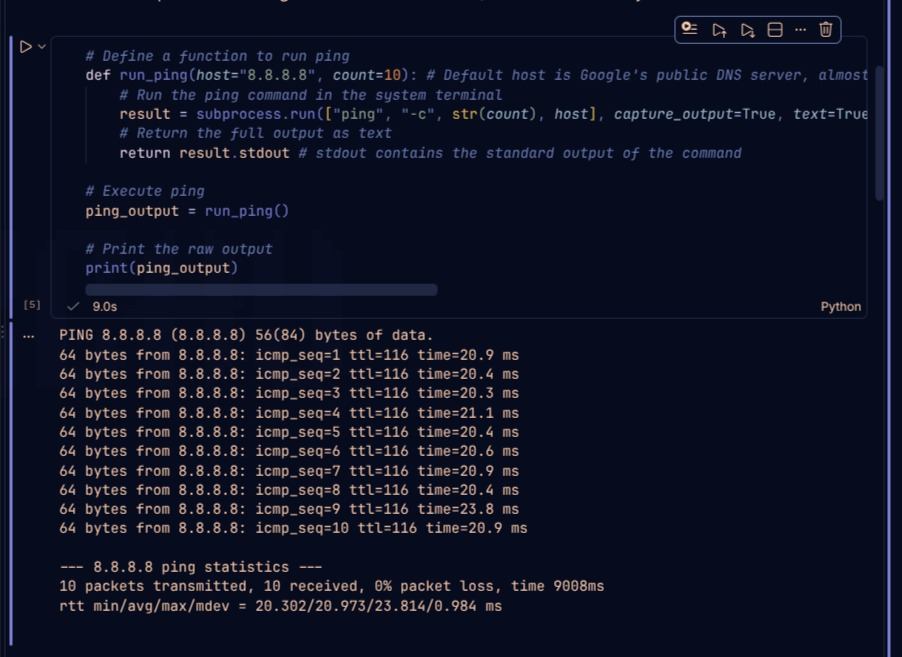
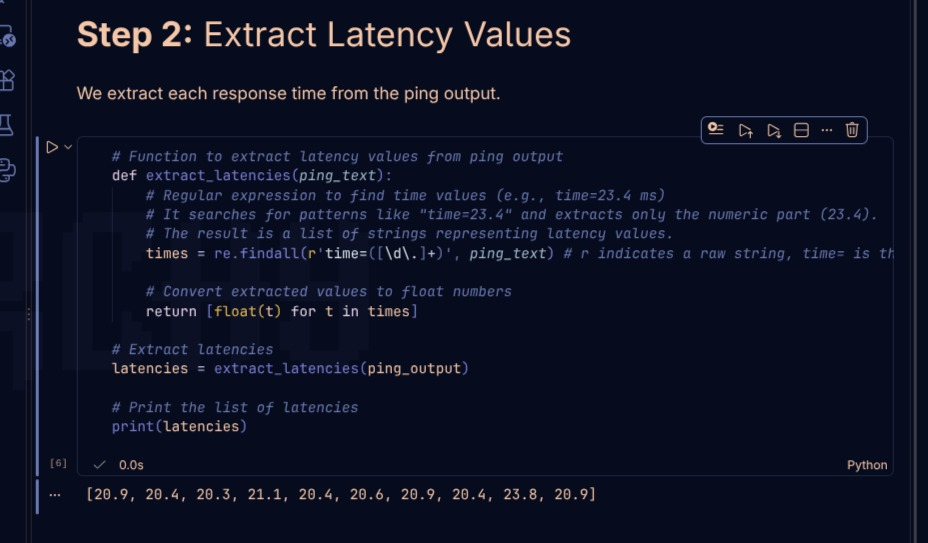
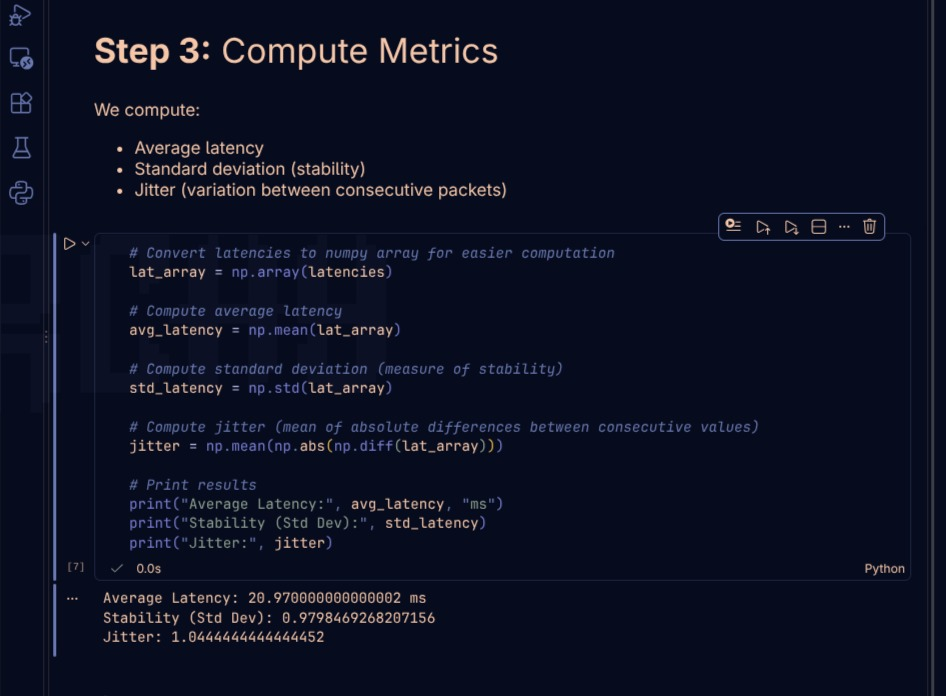
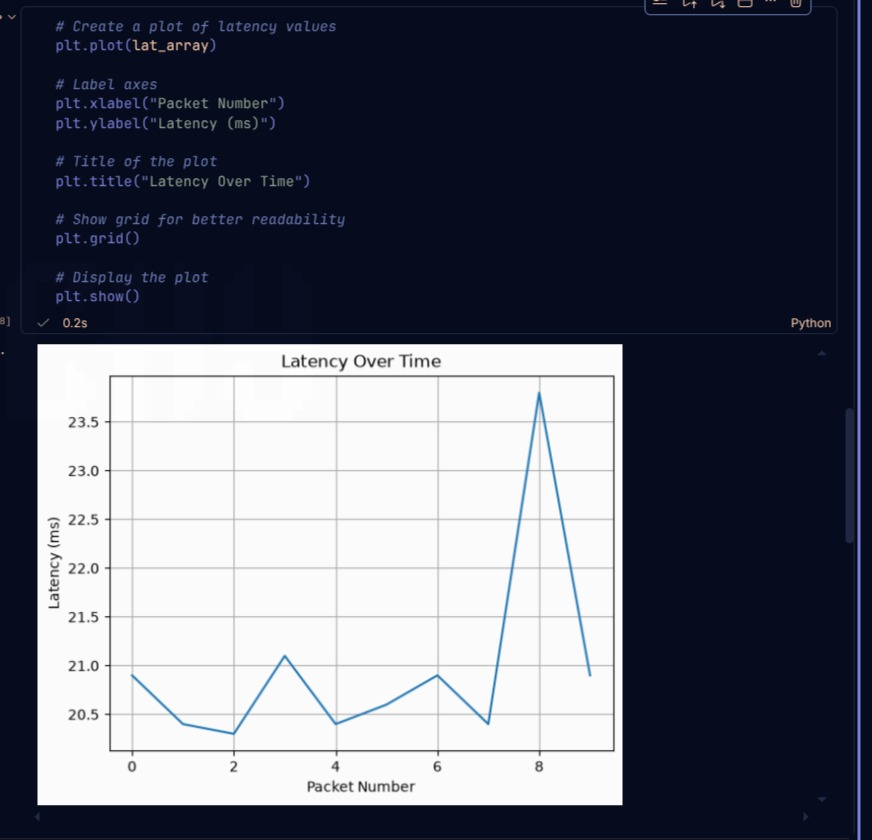


**Results of Mobile Data**
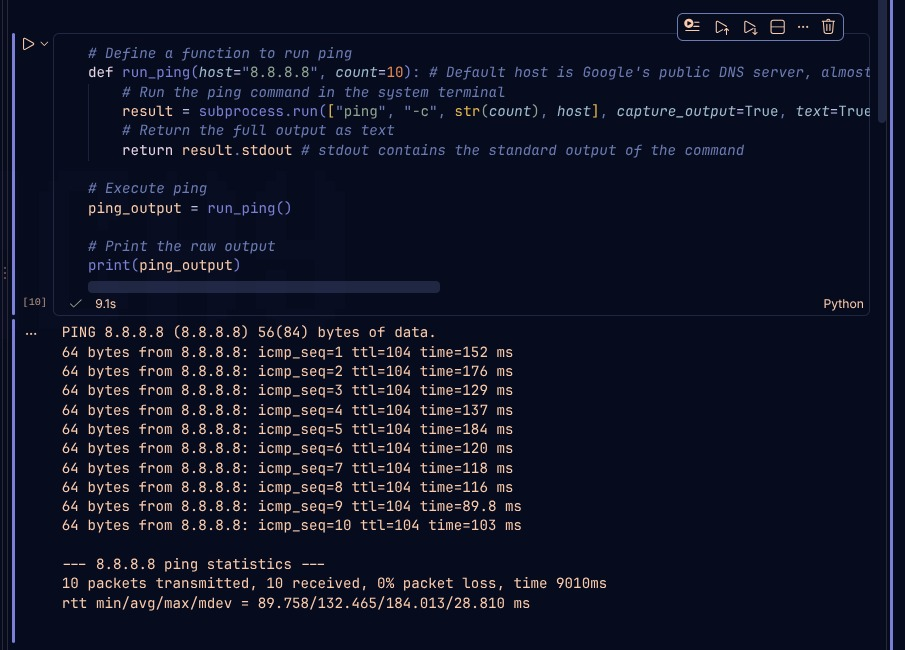
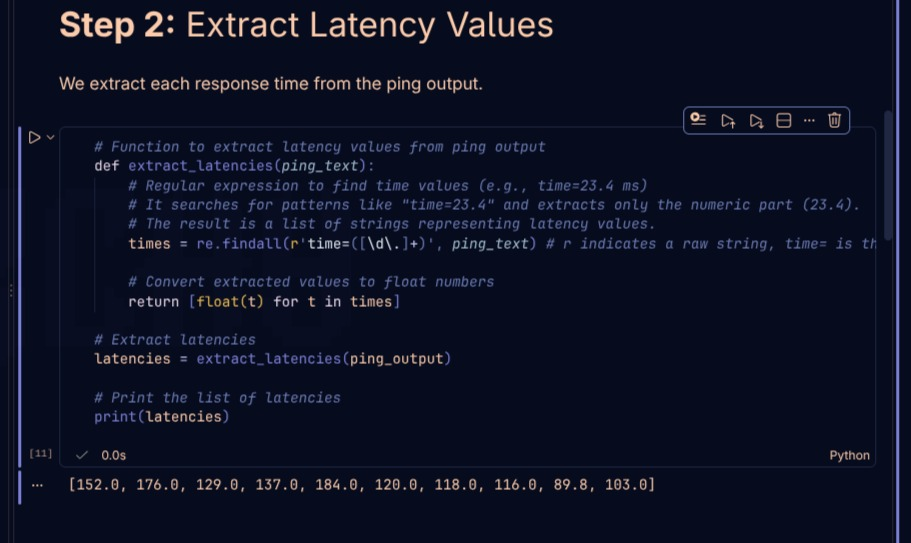
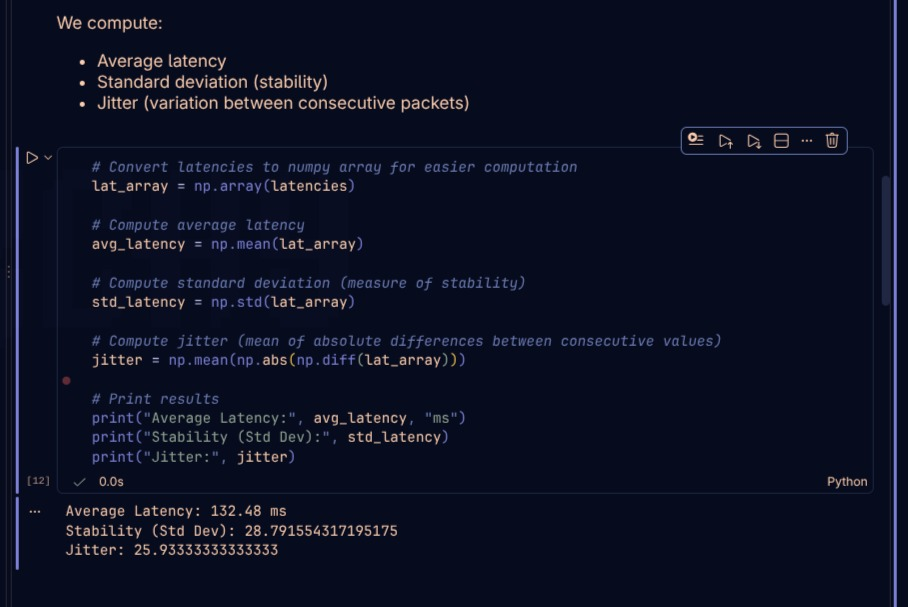
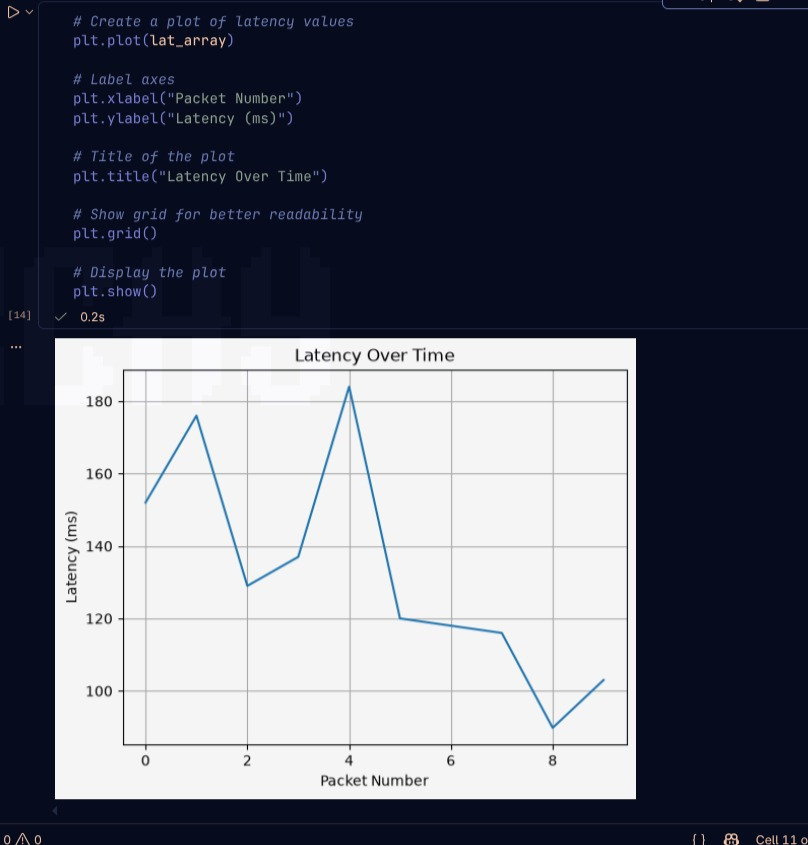


##  Results Comparison

| Metric | WiFi | Mobile Data |
|---|---|---|
| Average Latency | 20.97 ms | 132.48 ms |
| Standard Deviation | 0.98 ms | 28.79 ms |
| Jitter | 1.04 ms | 25.93 ms |
| Packet Loss | 0% | 0% |


